# Đ45 – Trạm thời tiết ảo cho nhà máy tại Đồng Nai (Open-Meteo)
Môn 115122 Dữ liệu & Phân tích – bài đánh giá cuối kỳ.
Chạy lại từ đầu: **Thời gian chạy → Chạy tất cả**. Seed cố định = 42; khoảng dữ liệu cố định 09/11/2023 – 08/11/2026.
Mỗi ô code đánh số "Ô n" để báo cáo trích dẫn.

In [1]:
# Ô 1 – Thiết lập, thư viện, hằng số, hạt giống ngẫu nhiên
import os, sys, json, time, math, sqlite3, secrets, threading, warnings
from datetime import date, timedelta
from http.server import BaseHTTPRequestHandler, HTTPServer
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

START, END = "2023-11-09", "2026-11-08"          # cố định để kết quả tái lập được
STATIONS = {                                      # 1 trạm chính + 3 khu vực khác ở Đồng Nai (cho Y8)
    "BienHoa":   (10.9574, 106.8426),
    "LongKhanh": (10.9333, 107.2333),
    "NhonTrach": (10.7167, 106.9000),
    "TanPhu":    (11.2700, 107.4300),
}
PRIMARY = "BienHoa"
TZ = "Asia/Bangkok"
HOURLY_VARS = ["temperature_2m", "relative_humidity_2m", "apparent_temperature",
               "shortwave_radiation", "precipitation", "wind_speed_10m"]
HEAT = 35.0          # ngưỡng nắng nóng (°C) – giả định spec tự đặt
SEVERE = 37.0        # nắng nóng gay gắt (°C)
BASE_CDH = 26.0      # cơ sở tính cooling degree-hours (°C) – giả định

for d in ("data", "figures", "apps_script"):
    Path(d).mkdir(exist_ok=True)

RES = {"meta": {"seed": SEED, "start": START, "end": END, "primary": PRIMARY,
                "stations": {k: list(v) for k, v in STATIONS.items()}}}


def _j(o):
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return None if np.isnan(o) else float(o)
    if isinstance(o, (np.bool_,)):
        return bool(o)
    if isinstance(o, (pd.Timestamp, date)):
        return str(o)[:10]
    if isinstance(o, np.ndarray):
        return o.tolist()
    return str(o)


def save_res():
    Path("results_d45.json").write_text(json.dumps(RES, ensure_ascii=False, indent=2, default=_j), encoding="utf-8")


def savefig(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150)
    plt.show()
    plt.close()


def r(x, nd=3):
    return None if x is None or (isinstance(x, float) and np.isnan(x)) else round(float(x), nd)


print("Ô 1 xong. Python", sys.version.split()[0], "| pandas", pd.__version__, "| seed", SEED)

Ô 1 xong. Python 3.13.18 | pandas 2.2.3 | seed 42


In [2]:
# Ô 2 – Lấy dữ liệu giờ từ Open-Meteo Historical Weather API (cache vào data/)
ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"


def get_json(url, params, retries=4):
    for i in range(retries):
        try:
            resp = requests.get(url, params=params, timeout=(15, 90))
            if resp.status_code == 429:
                time.sleep(5 * (i + 1))
                continue
            resp.raise_for_status()
            return resp.json()
        except requests.RequestException:
            if i == retries - 1:
                raise
            time.sleep(3 * (i + 1))


def fetch_station(name, lat, lon):
    f = Path(f"data/hourly_{name}.csv")
    if f.exists():
        return pd.read_csv(f, parse_dates=["time"])
    frames, cur, end = [], date.fromisoformat(START), date.fromisoformat(END)
    while cur <= end:
        ce = min(date(cur.year, 12, 31), end)
        js = get_json(ARCHIVE_URL, {"latitude": lat, "longitude": lon, "start_date": cur.isoformat(),
                                    "end_date": ce.isoformat(), "hourly": ",".join(HOURLY_VARS), "timezone": TZ})
        df = pd.DataFrame(js["hourly"])
        df["time"] = pd.to_datetime(df["time"])
        frames.append(df)
        cur = ce + timedelta(days=1)
        time.sleep(1)
    out = pd.concat(frames, ignore_index=True)
    out.to_csv(f, index=False)
    return out


HOURLY = {}
for name, (lat, lon) in STATIONS.items():
    HOURLY[name] = fetch_station(name, lat, lon)
    print(f"{name:10s}: {len(HOURLY[name]):6d} dòng giờ | {HOURLY[name]['time'].min()} → {HOURLY[name]['time'].max()}")

RES["data"] = {"rows_per_station": {k: len(v) for k, v in HOURLY.items()},
               "source": "https://open-meteo.com/en/docs/historical-weather-api",
               "endpoint": ARCHIVE_URL, "variables": HOURLY_VARS}
save_res()

BienHoa   :  26304 dòng giờ | 2023-11-09 00:00:00 → 2026-11-08 23:00:00
LongKhanh :  26304 dòng giờ | 2023-11-09 00:00:00 → 2026-11-08 23:00:00
NhonTrach :  26304 dòng giờ | 2023-11-09 00:00:00 → 2026-11-08 23:00:00
TanPhu    :  26304 dòng giờ | 2023-11-09 00:00:00 → 2026-11-08 23:00:00


BienHoa {'rows': 26304, 'duplicate_hours': 0, 'missing_hours': 0, 'nan_values': 0, 'zero_days': 0, 'out_of_range_hours': 0} → ĐẠT
LongKhanh {'rows': 26304, 'duplicate_hours': 0, 'missing_hours': 0, 'nan_values': 0, 'zero_days': 0, 'out_of_range_hours': 0} → ĐẠT
NhonTrach {'rows': 26304, 'duplicate_hours': 0, 'missing_hours': 0, 'nan_values': 0, 'zero_days': 0, 'out_of_range_hours': 0} → ĐẠT
TanPhu {'rows': 26304, 'duplicate_hours': 0, 'missing_hours': 0, 'nan_values': 0, 'zero_days': 0, 'out_of_range_hours': 0} → ĐẠT

Tiêm lỗi: {'duplicate_hours': 3, 'missing_hours': 96, 'nan_values': 20, 'zero_days': 33}
Cổng bắt được: {'duplicate_hours': 3, 'missing_hours': 96, 'nan_values': 20, 'zero_days': 33} | khớp: {'duplicate_hours': True, 'missing_hours': True, 'nan_values': True, 'zero_days': True}

Nhật ký làm sạch bản có lỗi tiêm:
  - loại dòng trùng mốc giờ: 3
  - giờ NaN sau khi bổ sung đủ mốc giờ (mất mốc + thiếu giá trị): 116
  - giờ thuộc ngày Tmax = 0 bất thường → NaN: 792
  - giờ ngo

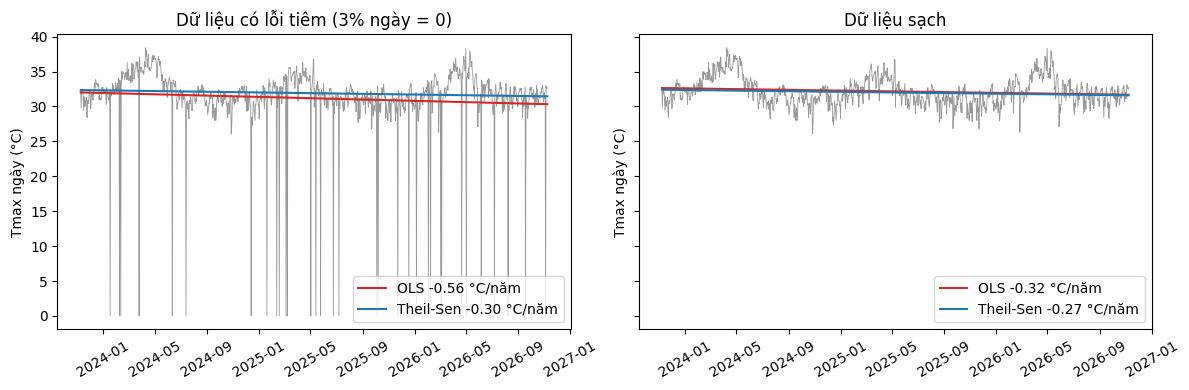

In [3]:
# Ô 3 – Y1: cổng kiểm tra dữ liệu, làm sạch, OLS so với Theil-Sen, chuyển bảng ngày sang JSON (xử lý NaN)
def quality_gate(h, start=START, end=END):
    h = h.copy()
    expected_hours = ((pd.Timestamp(end) - pd.Timestamp(start)).days + 1) * 24
    uniq = h.drop_duplicates("time")
    day = uniq["time"].dt.floor("D")
    daymax = uniq.groupby(day)["temperature_2m"].max()
    return {
        "rows": int(len(h)),
        "duplicate_hours": int(h.duplicated("time").sum()),
        "missing_hours": int(expected_hours - len(uniq)),
        "nan_values": int(uniq["temperature_2m"].isna().sum()),
        "zero_days": int((daymax == 0).sum()),
        "out_of_range_hours": int(((uniq["temperature_2m"] < 10) | (uniq["temperature_2m"] > 46)).sum()),
    }


def gate_ok(g):
    return all(g[k] == 0 for k in ("duplicate_hours", "missing_hours", "nan_values", "zero_days", "out_of_range_hours"))


def clean(h, start=START, end=END):
    """Trả về (bảng giờ sạch, nhật ký làm sạch)."""
    log = []
    n0 = len(h)
    h = h.drop_duplicates("time").sort_values("time")
    log.append(("loại dòng trùng mốc giờ", n0 - len(h)))
    full = pd.date_range(start, pd.Timestamp(end) + pd.Timedelta(hours=23), freq="h")
    h = h.set_index("time").reindex(full)
    h.index.name = "time"
    log.append(("giờ NaN sau khi bổ sung đủ mốc giờ (mất mốc + thiếu giá trị)", int(h["temperature_2m"].isna().sum())))
    day = h.index.floor("D")
    dmax = h["temperature_2m"].groupby(day).transform("max")
    zero_mask = dmax == 0
    log.append(("giờ thuộc ngày Tmax = 0 bất thường → NaN", int(zero_mask.sum())))
    h.loc[zero_mask, :] = np.nan
    bad = (h["temperature_2m"] < 10) | (h["temperature_2m"] > 46)
    log.append(("giờ ngoài khoảng 10–46 °C → NaN", int(bad.sum())))
    h.loc[bad, :] = np.nan
    before = int(h["temperature_2m"].isna().sum())
    h = h.interpolate(limit=3)
    log.append(("giờ NaN được nội suy (khoảng thiếu ≤ 3 giờ)", before - int(h["temperature_2m"].isna().sum())))
    log.append(("giờ NaN còn lại sau làm sạch", int(h["temperature_2m"].isna().sum())))
    return h.reset_index(), log


def make_daily(h):
    h = h.copy()
    h["day"] = h["time"].dt.floor("D")
    g = h.groupby("day")
    d = pd.DataFrame({
        "tmax": g["temperature_2m"].max(),
        "tmean": g["temperature_2m"].mean(),
        "rh_mean": g["relative_humidity_2m"].mean(),
        "rad_sum": g["shortwave_radiation"].sum(),
        "precip_sum": g["precipitation"].sum(),
        "cdh": g["temperature_2m"].apply(lambda s: (s - BASE_CDH).clip(lower=0).sum()),
        "hours": g["temperature_2m"].count(),
    })
    d.index.name = "date"
    return d


# 1) Cổng kiểm tra trên dữ liệu thật của mọi trạm
gate_real = {k: quality_gate(v) for k, v in HOURLY.items()}
for k, g in gate_real.items():
    print(k, g, "→", "ĐẠT" if gate_ok(g) else "KHÔNG ĐẠT")

# 2) Kiểm tra bản thân cổng: tiêm lỗi có chủ đích vào bản sao, xem cổng có bắt đủ không
dirty = HOURLY[PRIMARY].copy()
all_days = pd.Series(dirty["time"].dt.floor("D").unique())
pick = rng.choice(len(all_days), 33 + 4, replace=False)
zero_days = set(all_days.iloc[pick[:33]])
gap_days = set(all_days.iloc[pick[33:]])
dday = dirty["time"].dt.floor("D")
dirty = dirty[~dday.isin(gap_days)].copy()                       # 4 ngày mất mốc giờ → 96 giờ
dday = dirty["time"].dt.floor("D")
dirty.loc[dday.isin(zero_days), HOURLY_VARS] = 0.0               # 33 ngày (3%) bằng 0 bất thường
cand = dirty.index[~dday.isin(zero_days)]
nan_idx = rng.choice(cand, 20, replace=False)
dirty.loc[nan_idx, "temperature_2m"] = np.nan                    # 20 giờ thiếu giá trị
dirty = pd.concat([dirty, dirty.sample(3, random_state=SEED)], ignore_index=True)   # 3 dòng trùng
gate_dirty = quality_gate(dirty)
injected = {"duplicate_hours": 3, "missing_hours": 96, "nan_values": 20, "zero_days": 33}
caught = {k: (gate_dirty[k] == v) for k, v in injected.items()}
print("\nTiêm lỗi:", injected)
print("Cổng bắt được:", {k: gate_dirty[k] for k in injected}, "| khớp:", caught)

dirty_clean, clean_log = clean(dirty)
print("\nNhật ký làm sạch bản có lỗi tiêm:")
for a, n in clean_log:
    print(f"  - {a}: {n}")

# 3) Làm sạch dữ liệu thật của mọi trạm, tính bảng ngày
CLEAN, DAILY, CLEAN_LOG = {}, {}, {}
for k, v in HOURLY.items():
    CLEAN[k], CLEAN_LOG[k] = clean(v)
    DAILY[k] = make_daily(CLEAN[k])
daily = DAILY[PRIMARY]
y = daily["tmax"]
xdays = (daily.index - daily.index[0]).days.to_numpy().astype(float)

# 4) OLS và Theil-Sen: dữ liệu sạch và dữ liệu lỗi (chưa làm sạch, có 3% ngày bằng 0)
def fit_both(x, v):
    ok = ~np.isnan(v)
    o = stats.linregress(x[ok], v[ok])
    t = stats.theilslopes(v[ok], x[ok])
    return {"ols_slope_per_year": o.slope * 365.25, "ols_r2": o.rvalue ** 2, "ols_p": o.pvalue,
            "ts_slope_per_year": t.slope * 365.25, "ts_lo": t.low_slope * 365.25, "ts_hi": t.high_slope * 365.25}


fit_clean = fit_both(xdays, y.to_numpy())
dd = make_daily(dirty.drop_duplicates("time"))
xd = (dd.index - daily.index[0]).days.to_numpy().astype(float)
fit_dirty = fit_both(xd, dd["tmax"].to_numpy())
print("\nOLS vs Theil-Sen (độ dốc, °C/năm)")
print(f"  dữ liệu sạch : OLS {fit_clean['ols_slope_per_year']:.3f} | Theil-Sen {fit_clean['ts_slope_per_year']:.3f}")
print(f"  dữ liệu lỗi  : OLS {fit_dirty['ols_slope_per_year']:.3f} | Theil-Sen {fit_dirty['ts_slope_per_year']:.3f}")

# 5) Chuyển bảng ngày sang JSON, xử lý NaN
sample = daily.reset_index().head(5).copy()
sample["date"] = sample["date"].dt.strftime("%Y-%m-%d")
sample.loc[2, "tmax"] = np.nan          # cố tình tạo NaN
bad_json = json.dumps(sample.to_dict("records"))                   # sinh ra token NaN → JSON không hợp lệ


def to_json_records(df):
    out = df.copy()
    out = out.astype(object).where(out.notna(), None)              # NaN → None → null
    return json.loads(json.dumps(out.to_dict("records"), allow_nan=False, default=_j))


good = to_json_records(sample)
print("\nJSON mặc định chứa 'NaN':", "NaN" in bad_json, "| JSON đã xử lý hợp lệ (allow_nan=False):", good[2]["tmax"] is None)
full_json = to_json_records(daily.reset_index().assign(date=lambda d: d["date"].dt.strftime("%Y-%m-%d")))
Path("data/daily_sample.json").write_text(json.dumps(good[:5], ensure_ascii=False, indent=1), encoding="utf-8")
Path("data/daily.json").write_text(json.dumps(full_json, ensure_ascii=False), encoding="utf-8")
Path("data/cleaning_log.json").write_text(json.dumps({"real": CLEAN_LOG, "stress_test": clean_log, "gate_real": gate_real,
                                                      "gate_dirty": gate_dirty}, ensure_ascii=False, indent=1, default=_j), encoding="utf-8")
daily.to_csv("data/daily_bienhoa.csv")

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, (lab, dfx, xx, ft) in zip(ax, [("Dữ liệu có lỗi tiêm (3% ngày = 0)", dd, xd, fit_dirty),
                                       ("Dữ liệu sạch", daily, xdays, fit_clean)]):
    a.plot(dfx.index, dfx["tmax"], lw=.6, color="#999")
    x0 = dfx.index[0]
    xs = np.array([xx.min(), xx.max()])
    ok = ~np.isnan(dfx["tmax"].to_numpy())
    o = stats.linregress(xx[ok], dfx["tmax"].to_numpy()[ok])
    t = stats.theilslopes(dfx["tmax"].to_numpy()[ok], xx[ok])
    a.plot(x0 + pd.to_timedelta(xs, unit="D"), o.intercept + o.slope * xs, color="#d62728", label=f"OLS {ft['ols_slope_per_year']:+.2f} °C/năm")
    a.plot(x0 + pd.to_timedelta(xs, unit="D"), t.intercept + t.slope * xs, color="#1f77b4", label=f"Theil-Sen {ft['ts_slope_per_year']:+.2f} °C/năm")
    a.set(title=lab, ylabel="Tmax ngày (°C)")
    a.legend(loc="lower right")
    a.tick_params(axis="x", labelrotation=30)
savefig("y1_ols_vs_theilsen")

RES["Y1"] = {"gate_real": gate_real, "gate_real_all_ok": {k: gate_ok(g) for k, g in gate_real.items()},
             "injected": injected, "gate_dirty": gate_dirty, "gate_caught_all": all(caught.values()),
             "clean_log_stress": clean_log, "clean_log_real_primary": CLEAN_LOG[PRIMARY],
             "fit_clean": {k: r(v, 4) for k, v in fit_clean.items()}, "fit_dirty": {k: r(v, 4) for k, v in fit_dirty.items()},
             "json_default_has_nan": "NaN" in bad_json, "json_fixed_valid": True, "n_days": int(len(daily))}
save_res()

OLS Tmax ~ ngày: độ dốc -0.321 °C/năm (sai số chuẩn 0.069), R² = 0.0196, p = 3.258e-06
Sau khi bỏ mùa: độ dốc -0.181 °C/năm, R² = 0.0129, p = 0.000168

Độ trễ phát hiện bước nhảy +3.0 °C (chèn ngày 2025-07-01):
 window  threshold  lag_days  false_alarm_days_before
      3      3.355         3                        0
      7      2.874         5                        0
     30      2.113        22                        0


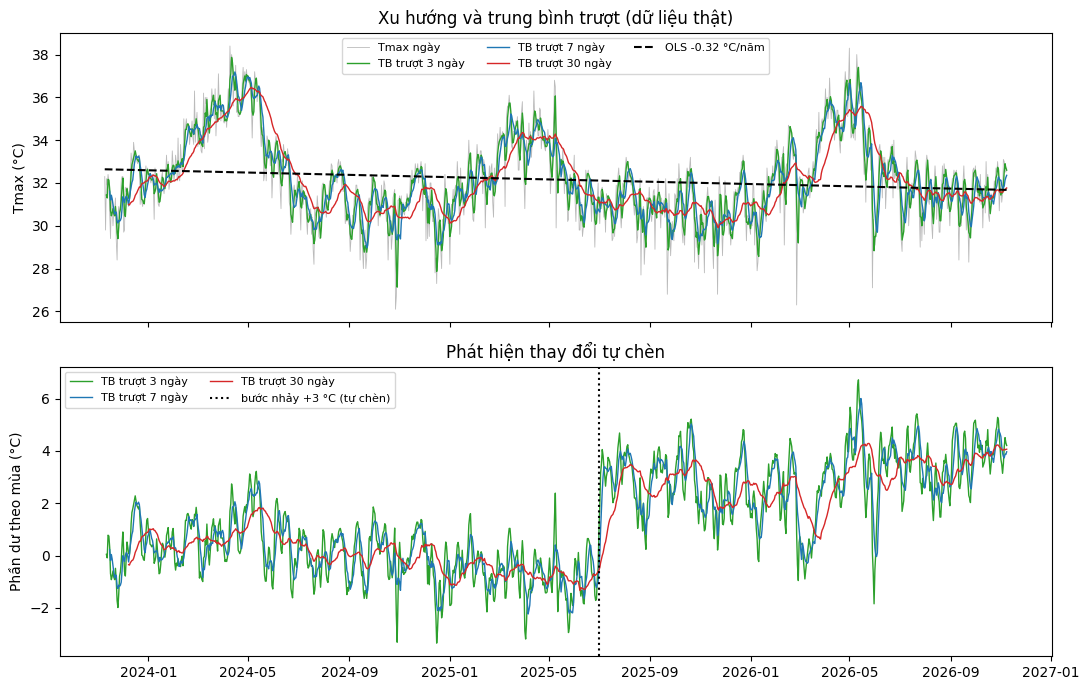

In [4]:
# Ô 4 – Y2: hồi quy xu hướng Tmax theo ngày; trung bình trượt 3 cửa sổ; độ trễ phát hiện một thay đổi
res = stats.linregress(xdays, y.to_numpy())
trend = {"slope_per_day": res.slope, "slope_per_year": res.slope * 365.25, "r2": res.rvalue ** 2, "p": res.pvalue,
         "stderr_per_year": res.stderr * 365.25, "n": int(len(y))}
print(f"OLS Tmax ~ ngày: độ dốc {trend['slope_per_year']:+.3f} °C/năm (sai số chuẩn {trend['stderr_per_year']:.3f}), R² = {trend['r2']:.4f}, p = {trend['p']:.4g}")

# xu hướng sau khi loại thành phần mùa (trung bình theo tháng)
clim = y.groupby(y.index.month).transform("mean")
anom = y - clim
ra = stats.linregress(xdays, anom.to_numpy())
trend["anomaly_slope_per_year"] = ra.slope * 365.25
trend["anomaly_r2"] = ra.rvalue ** 2
trend["anomaly_p"] = ra.pvalue
print(f"Sau khi bỏ mùa: độ dốc {trend['anomaly_slope_per_year']:+.3f} °C/năm, R² = {trend['anomaly_r2']:.4f}, p = {trend['anomaly_p']:.4g}")

# thay đổi tự chèn: bước nhảy +3 °C từ 01/07/2025; phát hiện bằng MA 3, 7, 30 ngày trên phần dư theo mùa
SHIFT_DATE, SHIFT_SIZE, SIGMA_K = pd.Timestamp("2025-07-01"), 3.0, 3.0
ys = y.copy()
ys[ys.index >= SHIFT_DATE] += SHIFT_SIZE
si = int((ys.index >= SHIFT_DATE).argmax())
clim_pre = y[y.index < SHIFT_DATE].groupby(y[y.index < SHIFT_DATE].index.month).mean()
resid = ys - ys.index.month.map(clim_pre).to_numpy()
lag_rows = []
for w in (3, 7, 30):
    ma = resid.rolling(w).mean()
    base = ma.iloc[w:si]
    thr = base.mean() + SIGMA_K * base.std()
    false_alarm = int((base > thr).sum())
    hit = np.where(ma.iloc[si:].to_numpy() > thr)[0]
    lag = int(hit[0]) if len(hit) else None
    lag_rows.append({"window": w, "threshold": r(thr), "lag_days": lag, "false_alarm_days_before": false_alarm})
print("\nĐộ trễ phát hiện bước nhảy +%.1f °C (chèn ngày %s):" % (SHIFT_SIZE, SHIFT_DATE.date()))
print(pd.DataFrame(lag_rows).to_string(index=False))

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax[0].plot(y.index, y, lw=.6, color="#bbb", label="Tmax ngày")
for w, c in zip((3, 7, 30), ("#2ca02c", "#1f77b4", "#d62728")):
    ax[0].plot(y.index, y.rolling(w).mean(), lw=1, color=c, label=f"TB trượt {w} ngày")
ax[0].plot(y.index, res.intercept + res.slope * xdays, "k--", label=f"OLS {trend['slope_per_year']:+.2f} °C/năm")
ax[0].set(ylabel="Tmax (°C)", title="Xu hướng và trung bình trượt (dữ liệu thật)")
ax[0].legend(ncol=3, fontsize=8)
for w, c in zip((3, 7, 30), ("#2ca02c", "#1f77b4", "#d62728")):
    ax[1].plot(resid.index, resid.rolling(w).mean(), lw=1, color=c, label=f"TB trượt {w} ngày")
ax[1].axvline(SHIFT_DATE, color="k", ls=":", label=f"bước nhảy +{SHIFT_SIZE:.0f} °C (tự chèn)")
ax[1].set(ylabel="Phần dư theo mùa (°C)", title="Phát hiện thay đổi tự chèn")
ax[1].legend(ncol=2, fontsize=8)
savefig("y2_trend_ma")
RES["Y2"] = {"trend": {k: r(v, 5) for k, v in trend.items()}, "shift": {"date": SHIFT_DATE, "size": SHIFT_SIZE, "sigma_k": SIGMA_K},
             "detection": lag_rows}
save_res()

MAE (°C) theo chân trời dự báo:
          Phương pháp  MAE h=1  MAE h=7  MAE h=14  MAE h=28
             Hôm qua    0.869    1.385     1.435     1.717
Cùng ngày tuần trước    1.380    1.385     1.435     1.717
     TB trượt 7 ngày    0.969    1.185     1.324     1.522
    Xu hướng 28 ngày    1.022    1.407     1.772     2.492

MAE h=1 theo loại ngày:
          Phương pháp  MAE toàn bộ  MAE ngày thường  MAE cuối tuần
             Hôm qua        0.869            0.851          0.913
Cùng ngày tuần trước        1.380            1.360          1.432
     TB trượt 7 ngày        0.969            0.942          1.035
    Xu hướng 28 ngày        1.022            1.011          1.048

Độ phủ khoảng ±2σ (σ hiệu chuẩn trên 365 gốc đầu, kiểm tra trên phần còn lại; mục tiêu ≈ 0,95):
          Phương pháp  phủ ±2σ h=1  phủ ±2σ h=7  phủ ±2σ h=14  phủ ±2σ h=28
             Hôm qua        0.933        0.910         0.945         0.963
Cùng ngày tuần trước        0.897        0.910         0.945        

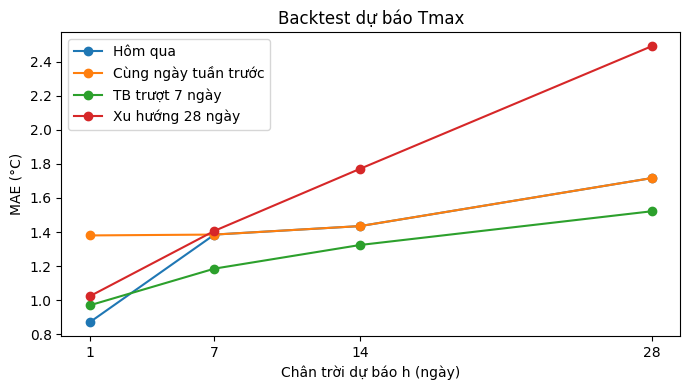

In [5]:
# Ô 5 – Y3: backtest 4 phương pháp dự báo Tmax; MAE theo ngày thường/cuối tuần; MAE theo chân trời; độ phủ ±2σ
yv = y.to_numpy()
N, T0, HORIZONS = len(yv), 60, [1, 7, 14, 28]


def f_naive(t, h): return yv[t]
def f_week(t, h): return yv[t + h - 7 * math.ceil(h / 7)]
def f_ma7(t, h): return yv[t - 6:t + 1].mean()


def f_trend(t, h):
    b, a = np.polyfit(np.arange(28), yv[t - 27:t + 1], 1)
    return a + b * (27 + h)


METHODS = {"Hôm qua": f_naive, "Cùng ngày tuần trước": f_week, "TB trượt 7 ngày": f_ma7, "Xu hướng 28 ngày": f_trend}
ERR = {}
for h in HORIZONS:
    origins = np.arange(T0, N - h)
    for m, f in METHODS.items():
        ERR[(m, h)] = (origins, np.array([yv[t + h] - f(t, h) for t in origins]))

rows_mae = []
for m in METHODS:
    row = {"Phương pháp": m}
    for h in HORIZONS:
        row[f"MAE h={h}"] = r(np.abs(ERR[(m, h)][1]).mean())
    rows_mae.append(row)
mae_df = pd.DataFrame(rows_mae)
print("MAE (°C) theo chân trời dự báo:\n", mae_df.to_string(index=False))

rows_wd = []
for m in METHODS:
    o, e = ERR[(m, 1)]
    dow = daily.index[o + 1].dayofweek
    rows_wd.append({"Phương pháp": m, "MAE toàn bộ": r(np.abs(e).mean()), "MAE ngày thường": r(np.abs(e[dow < 5]).mean()),
                    "MAE cuối tuần": r(np.abs(e[dow >= 5]).mean())})
wd_df = pd.DataFrame(rows_wd)
print("\nMAE h=1 theo loại ngày:\n", wd_df.to_string(index=False))

rows_cov = []
for m in METHODS:
    row = {"Phương pháp": m}
    for h in HORIZONS:
        o, e = ERR[(m, h)]
        cal = o < T0 + 365                                # hiệu chuẩn σ trên 365 gốc đầu → không rò rỉ sang phần kiểm tra
        sd = e[cal].std()
        row[f"phủ ±2σ h={h}"] = r((np.abs(e[~cal]) <= 2 * sd).mean(), 3)
    rows_cov.append(row)
cov_df = pd.DataFrame(rows_cov)
print("\nĐộ phủ khoảng ±2σ (σ hiệu chuẩn trên 365 gốc đầu, kiểm tra trên phần còn lại; mục tiêu ≈ 0,95):\n", cov_df.to_string(index=False))
best = {f"h={h}": mae_df.loc[mae_df[f"MAE h={h}"].idxmin(), "Phương pháp"] for h in HORIZONS}
print("\nPhương pháp tốt nhất theo chân trời:", best)

fig, ax = plt.subplots(figsize=(7, 4))
for m in METHODS:
    ax.plot(HORIZONS, [mae_df.loc[mae_df["Phương pháp"] == m, f"MAE h={h}"].iloc[0] for h in HORIZONS], marker="o", label=m)
ax.set(xlabel="Chân trời dự báo h (ngày)", ylabel="MAE (°C)", title="Backtest dự báo Tmax", xticks=HORIZONS)
ax.legend()
savefig("y3_backtest_mae")
RES["Y3"] = {"mae": mae_df.to_dict("records"), "weekday_weekend": wd_df.to_dict("records"), "coverage": cov_df.to_dict("records"),
             "best": best, "note_weekly_equals_naive": "với h = 7, 14, 28 phương pháp 'cùng ngày tuần trước' trùng với 'hôm qua' (cùng dùng y[t])", "n_origins_h1": int(len(ERR[("Hôm qua", 1)][0]))}
save_res()

                         Biến       Phiên bản    n  Pearson r   p (Pearson)  Spearman ρ  p (Spearman)
         độ ẩm trung bình (%)       Mức (gốc) 1096     -0.659 2.350000e-137      -0.687 6.100000e-154
         độ ẩm trung bình (%) Sai phân (diff) 1095     -0.486  5.220000e-66      -0.472  5.640000e-62
bức xạ sóng ngắn (Wh/m²/ngày)       Mức (gốc) 1096      0.769 6.900000e-215       0.793 1.190000e-237
bức xạ sóng ngắn (Wh/m²/ngày) Sai phân (diff) 1095      0.737 7.610000e-188       0.667 5.650000e-142


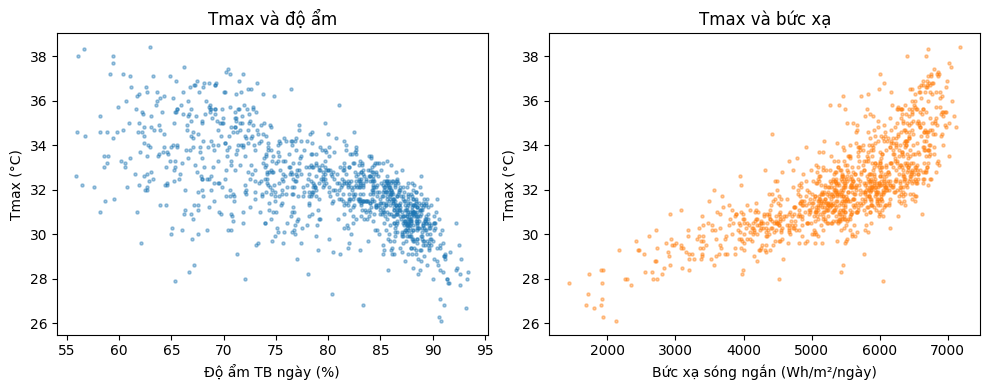

In [6]:
# Ô 6 – Y4: tương quan Tmax với độ ẩm, bức xạ (Pearson, Spearman, p-value); kiểm tra tương quan giả bằng sai phân
pairs = {"độ ẩm trung bình (%)": "rh_mean", "bức xạ sóng ngắn (Wh/m²/ngày)": "rad_sum"}
rows_c = []
for lab, col in pairs.items():
    for version, (a, b) in {"Mức (gốc)": (y, daily[col]),
                            "Sai phân (diff)": (y.diff().dropna(), daily[col].diff().dropna())}.items():
        pr, pp = stats.pearsonr(a, b)
        sr, sp = stats.spearmanr(a, b)
        rows_c.append({"Biến": lab, "Phiên bản": version, "n": len(a), "Pearson r": r(pr), "p (Pearson)": float(f"{pp:.3g}"),
                       "Spearman ρ": r(sr), "p (Spearman)": float(f"{sp:.3g}")})
corr_df = pd.DataFrame(rows_c)
print(corr_df.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(daily["rh_mean"], y, s=5, alpha=.4)
ax[0].set(xlabel="Độ ẩm TB ngày (%)", ylabel="Tmax (°C)", title="Tmax và độ ẩm")
ax[1].scatter(daily["rad_sum"], y, s=5, alpha=.4, color="#ff7f0e")
ax[1].set(xlabel="Bức xạ sóng ngắn (Wh/m²/ngày)", ylabel="Tmax (°C)", title="Tmax và bức xạ")
savefig("y4_correlation")
RES["Y4"] = {"table": corr_df.to_dict("records")}
save_res()

ANOVA 12 tháng: F = 103.73, p = 1.05e-160, η² = 0.513
Levene (đồng nhất phương sai): W = 5.89, p = 2.36e-09
Tukey HSD: 44/66 cặp khác biệt (p<0,05)
Welch từng cặp: 54/66 cặp có p<0,05 trước hiệu chỉnh → 44/66 sau Bonferroni (ngưỡng 0.00076)

Mùa mưa vs khô: TB 31.67 vs 32.66 °C, Welch t = -8.52, p = 5.41e-17, Cohen d = -0.52
Tương quan Tmax–độ ẩm:  {'gộp cả năm': np.float64(-0.659), 'Mùa mưa (T5–T10)': np.float64(-0.837), 'Mùa khô (T11–T4)': np.float64(-0.574)}


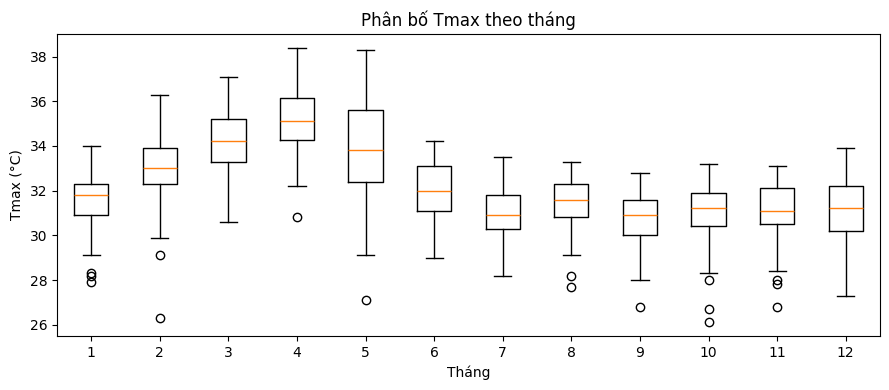

In [7]:
# Ô 7 – Y5: so sánh Tmax giữa các tháng và giữa mùa mưa/khô: ANOVA, Levene, Tukey, Bonferroni, biến ẩn
dfm = daily.copy()
dfm["month"] = dfm.index.month
groups = [dfm.loc[dfm["month"] == m, "tmax"].to_numpy() for m in range(1, 13)]
F, pF = stats.f_oneway(*groups)
lev = stats.levene(*groups)
allv = np.concatenate(groups)
ssb = sum(len(g) * (g.mean() - allv.mean()) ** 2 for g in groups)
eta2 = ssb / ((allv - allv.mean()) ** 2).sum()
tk = stats.tukey_hsd(*groups)
iu = np.triu_indices(12, 1)
n_pairs = len(iu[0])
sig_tukey = int((tk.pvalue[iu] < 0.05).sum())
pw = np.array([stats.ttest_ind(groups[i], groups[j], equal_var=False).pvalue for i, j in zip(*iu)])
sig_raw, sig_bonf = int((pw < 0.05).sum()), int((pw * n_pairs < 0.05).sum())
print(f"ANOVA 12 tháng: F = {F:.2f}, p = {pF:.3g}, η² = {eta2:.3f}")
print(f"Levene (đồng nhất phương sai): W = {lev.statistic:.2f}, p = {lev.pvalue:.3g}")
print(f"Tukey HSD: {sig_tukey}/{n_pairs} cặp khác biệt (p<0,05)")
print(f"Welch từng cặp: {sig_raw}/{n_pairs} cặp có p<0,05 trước hiệu chỉnh → {sig_bonf}/{n_pairs} sau Bonferroni (ngưỡng {0.05 / n_pairs:.5f})")

dfm["season"] = np.where(dfm["month"].between(5, 10), "Mùa mưa (T5–T10)", "Mùa khô (T11–T4)")
a_, b_ = (dfm.loc[dfm["season"] == s, "tmax"] for s in ("Mùa mưa (T5–T10)", "Mùa khô (T11–T4)"))
tt = stats.ttest_ind(a_, b_, equal_var=False)
cohen_d = (a_.mean() - b_.mean()) / math.sqrt((a_.var(ddof=1) + b_.var(ddof=1)) / 2)
print(f"\nMùa mưa vs khô: TB {a_.mean():.2f} vs {b_.mean():.2f} °C, Welch t = {tt.statistic:.2f}, p = {tt.pvalue:.3g}, Cohen d = {cohen_d:.2f}")

conf = {"gộp cả năm": stats.pearsonr(dfm["tmax"], dfm["rh_mean"])[0]}
for s in ("Mùa mưa (T5–T10)", "Mùa khô (T11–T4)"):
    sub = dfm[dfm["season"] == s]
    conf[s] = stats.pearsonr(sub["tmax"], sub["rh_mean"])[0]
print("Tương quan Tmax–độ ẩm: ", {k: round(v, 3) for k, v in conf.items()})

fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot(groups)
ax.set_xticklabels(range(1, 13))
ax.set(xlabel="Tháng", ylabel="Tmax (°C)", title="Phân bố Tmax theo tháng")
savefig("y5_anova_boxplot")
RES["Y5"] = {"anova": {"F": r(F, 2), "p": float(f"{pF:.3g}"), "eta2": r(eta2), "n_groups": 12},
             "levene": {"W": r(lev.statistic, 2), "p": float(f"{lev.pvalue:.3g}")},
             "tukey_sig_pairs": sig_tukey, "n_pairs": n_pairs, "welch_sig_raw": sig_raw, "welch_sig_bonferroni": sig_bonf,
             "season": {"rainy_mean": r(a_.mean(), 2), "dry_mean": r(b_.mean(), 2), "t": r(tt.statistic, 2),
                        "p": float(f"{tt.pvalue:.3g}"), "cohen_d": r(cohen_d, 2)},
             "corr_tmax_rh": {k: r(v) for k, v in conf.items()},
             "month_means": {int(m): r(g.mean(), 2) for m, g in zip(range(1, 13), groups)}}
save_res()

  vòng 0: 13 tuần, X̿ = 31.87, R̄ = 2.07, X̄ ∈ [31.01; 32.74], ngoài giới hạn: 4
  vòng 1: 9 tuần, X̿ = 31.93, R̄ = 2.02, X̄ ∈ [31.08; 32.77], ngoài giới hạn: 0
Giai đoạn I: giữ 9/13 tuần (bỏ 4 tuần ngoài giới hạn)
Giai đoạn II (143 tuần): X̄ ngoài giới hạn 91 (64%); R ngoài giới hạn 15 (10%)

Năng lực với spec [25; 35] °C: giai đoạn I σ_trong = R̄/d2 = 0.75 → Cp = 2.23, Cpk = 1.37
Toàn bộ 3 năm: TB = 32.16, σ_tổng = 1.99 → Pp = 0.84, Ppk = 0.48; tỷ lệ ngày Tmax > 35 °C = 9.2%
Đối chứng – nhóm con 4 số đọc/ngày: 41/90 điểm giai đoạn I ngoài giới hạn → chia nhóm con sai làm giới hạn quá hẹp


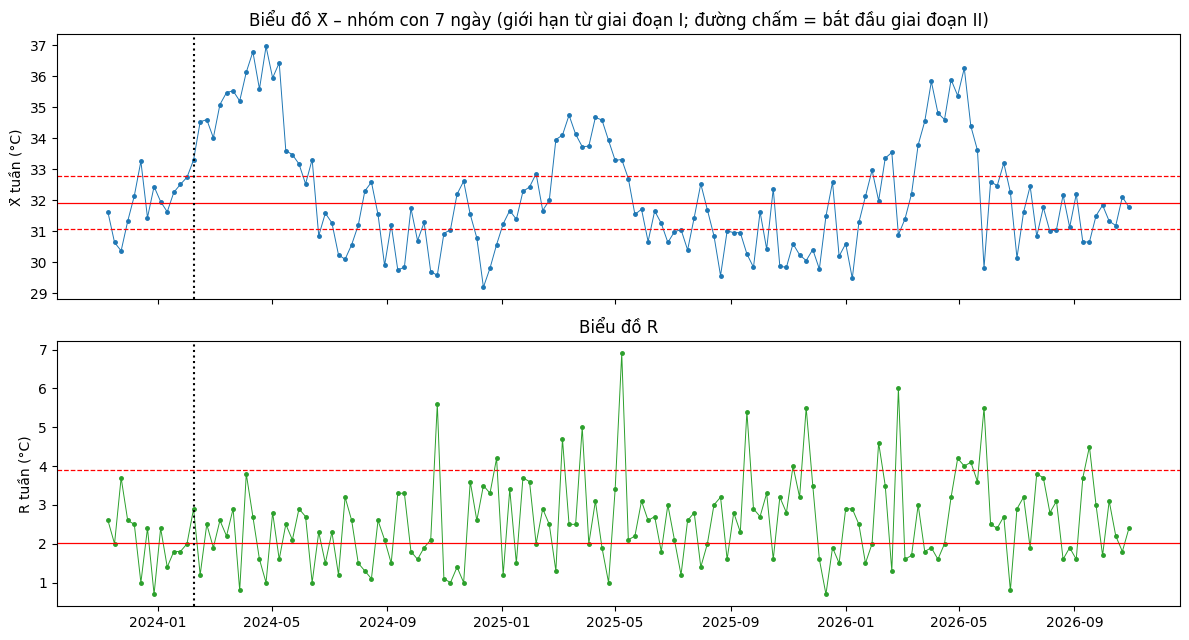

In [8]:
# Ô 8 – Y6: biểu đồ X-bar/R (giai đoạn I/II) và năng lực quá trình Cp/Cpk so với ngưỡng 35 °C
# Nhóm con hợp lý: 7 ngày liên tiếp (n = 7). Hằng số: A2 = 0,419; D3 = 0,076; D4 = 1,924; d2 = 2,704.
N_SUB, A2, D3, D4, d2 = 7, 0.419, 0.076, 1.924, 2.704
K_SUB = len(y) // N_SUB
M = y.iloc[:K_SUB * N_SUB].to_numpy().reshape(K_SUB, N_SUB)
wk_start = y.index[:K_SUB * N_SUB:N_SUB]
xbar, rng_ = M.mean(axis=1), M.max(axis=1) - M.min(axis=1)
PH1 = 13                                                 # giai đoạn I: 13 tuần đầu (09/11/2023 – 07/02/2024), mùa mát


def limits(idx):
    xbb, rbar = xbar[idx].mean(), rng_[idx].mean()
    return xbb, rbar, xbb - A2 * rbar, xbb + A2 * rbar, D3 * rbar, D4 * rbar


idx = np.arange(PH1)
removed = []
for it in range(5):                                      # dọn giai đoạn I: bỏ nhóm con ngoài giới hạn rồi tính lại
    xbb, rbar, LCLx, UCLx, LCLr, UCLr = limits(idx)
    bad = (xbar[idx] < LCLx) | (xbar[idx] > UCLx) | (rng_[idx] > UCLr) | (rng_[idx] < LCLr)
    print(f"  vòng {it}: {len(idx)} tuần, X̿ = {xbb:.2f}, R̄ = {rbar:.2f}, X̄ ∈ [{LCLx:.2f}; {UCLx:.2f}], ngoài giới hạn: {int(bad.sum())}")
    if not bad.any():
        break
    removed.append(int(bad.sum()))
    idx = idx[~bad]
rest = np.arange(PH1, K_SUB)
oc_x = int(((xbar[rest] < LCLx) | (xbar[rest] > UCLx)).sum())
oc_r = int((rng_[rest] > UCLr).sum())
print(f"Giai đoạn I: giữ {len(idx)}/{PH1} tuần (bỏ {sum(removed)} tuần ngoài giới hạn)")
print(f"Giai đoạn II ({len(rest)} tuần): X̄ ngoài giới hạn {oc_x} ({oc_x / len(rest):.0%}); R ngoài giới hạn {oc_r} ({oc_r / len(rest):.0%})")

USL, LSL = HEAT, 25.0                                    # spec tự đặt cho Tmax ngày: [25; 35] °C
sig_w = rbar / d2
mean1 = xbb
cp = (USL - LSL) / (6 * sig_w)
cpk = min((USL - mean1) / (3 * sig_w), (mean1 - LSL) / (3 * sig_w))
mean_all, sd_all = float(y.mean()), float(y.std(ddof=1))
pp = (USL - LSL) / (6 * sd_all)
ppk = min((USL - mean_all) / (3 * sd_all), (mean_all - LSL) / (3 * sd_all))
share_over = float((y > USL).mean())
print(f"\nNăng lực với spec [{LSL:.0f}; {USL:.0f}] °C: giai đoạn I σ_trong = R̄/d2 = {sig_w:.2f} → Cp = {cp:.2f}, Cpk = {cpk:.2f}")
print(f"Toàn bộ 3 năm: TB = {mean_all:.2f}, σ_tổng = {sd_all:.2f} → Pp = {pp:.2f}, Ppk = {ppk:.2f}; tỷ lệ ngày Tmax > {USL:.0f} °C = {share_over:.1%}")

# đối chứng: nhóm con "4 số đọc trong một ngày" (12–15 h) → giới hạn quá hẹp vì bỏ qua biến thiên giữa các ngày
hb = CLEAN[PRIMARY].copy()
hb["day"] = hb["time"].dt.floor("D")
pk = hb[hb["time"].dt.hour.isin([12, 13, 14, 15])].pivot_table(index="day", columns=hb["time"].dt.hour, values="temperature_2m")
xb_d, r_d = pk.mean(axis=1), pk.max(axis=1) - pk.min(axis=1)
xbb_d, rb_d = xb_d.iloc[:90].mean(), r_d.iloc[:90].mean()
lo_d, hi_d = xbb_d - 0.729 * rb_d, xbb_d + 0.729 * rb_d
oc_d1 = int(((xb_d.iloc[:90] < lo_d) | (xb_d.iloc[:90] > hi_d)).sum())
print(f"Đối chứng – nhóm con 4 số đọc/ngày: {oc_d1}/90 điểm giai đoạn I ngoài giới hạn → chia nhóm con sai làm giới hạn quá hẹp")

fig, ax = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
ax[0].plot(wk_start, xbar, marker="o", ms=2.5, lw=.7, color="#1f77b4")
for v, ls in ((xbb, "-"), (UCLx, "--"), (LCLx, "--")):
    ax[0].axhline(v, color="r", ls=ls, lw=.9)
ax[0].axvline(wk_start[PH1], color="k", ls=":")
ax[0].set(ylabel="X̄ tuần (°C)", title="Biểu đồ X̄ – nhóm con 7 ngày (giới hạn từ giai đoạn I; đường chấm = bắt đầu giai đoạn II)")
ax[1].plot(wk_start, rng_, marker="o", ms=2.5, lw=.7, color="#2ca02c")
ax[1].axhline(rbar, color="r", lw=.9)
ax[1].axhline(UCLr, color="r", ls="--", lw=.9)
ax[1].axvline(wk_start[PH1], color="k", ls=":")
ax[1].set(ylabel="R tuần (°C)", title="Biểu đồ R")
savefig("y6_xbar_r")
RES["Y6"] = {"subgroup": "7 ngày liên tiếp (n=7)", "constants": {"A2": A2, "D3": D3, "D4": D4, "d2": d2}, "n_subgroups": int(K_SUB),
             "phase1_weeks": PH1, "phase1_kept": int(len(idx)), "phase1_removed": int(sum(removed)),
             "xbarbar": r(xbb), "rbar": r(rbar), "limits_x": [r(LCLx), r(UCLx)], "limits_r": [r(LCLr), r(UCLr)],
             "phase2_weeks": int(len(rest)), "oc_phase2_x": oc_x, "oc_phase2_r": oc_r,
             "spec": [LSL, USL], "sigma_within": r(sig_w), "Cp": r(cp, 2), "Cpk": r(cpk, 2),
             "mean_all": r(mean_all, 2), "sigma_overall": r(sd_all), "Pp": r(pp, 2), "Ppk": r(ppk, 2), "share_over_usl": r(share_over, 4),
             "control_within_day_subgroup": {"phase1_out_of_90": oc_d1}}
save_res()

Số sự kiện (ngày mai Tmax ≥ 35 °C): 113/1096
 k (ngày)  s  ngưỡng TB (°C)  TP  FP  FN  TN  báo động giả (FP/(FP+TN))  bỏ sót (FN/(TP+FN))  precision
        3  1            33.0 112 182   1 798                      0.186                0.009      0.381
        3  1            34.0 105  87   8 893                      0.089                0.071      0.547
        3  1            35.0  81  23  32 957                      0.023                0.283      0.779
        7  1            33.0 112 170   1 806                      0.174                0.009      0.397
        7  1            34.0 104  86   9 890                      0.088                0.080      0.547
        7  1            35.0  75  28  38 948                      0.029                0.336      0.728

Dung lượng truyền (4 trạm, 3 năm): {'raw_bytes_per_record': 179, 'feature_bytes_per_record': 93, 'raw_total_MB': 18.83, 'feature_total_MB': 0.408, 'raw_x10_MB': 188.3, 'feature_x10_MB': 4.08, 'reduction_factor': 46.2}


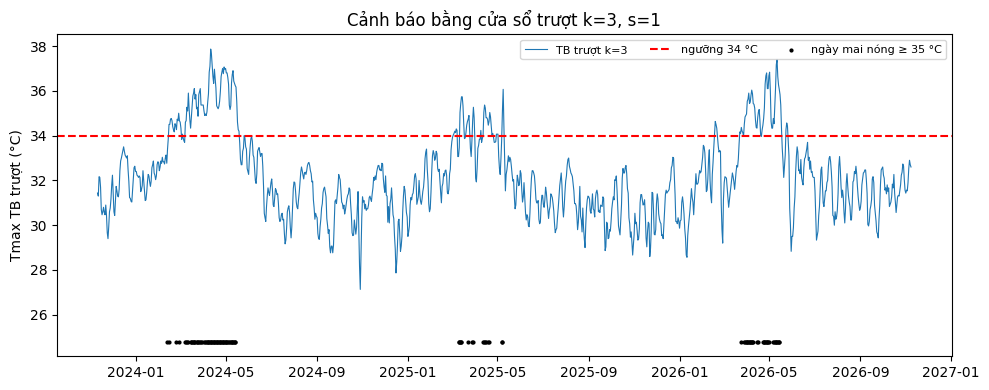

In [9]:
# Ô 9 – Y7: phát hiện bất thường bằng cửa sổ trượt (k, s) và ngưỡng; bảng báo động giả/bỏ sót; ước tính dung lượng ×10
event = (y.shift(-1) >= HEAT)                           # sự kiện định nghĩa: NGÀY MAI có Tmax ≥ 35 °C
rows_a = []
for k in (3, 7):
    wm = y.rolling(k).mean()                            # cửa sổ k ngày, bước s = 1 ngày
    for th in (33.0, 34.0, 35.0):
        alarm = wm >= th
        valid = wm.notna() & y.shift(-1).notna()
        a, e = alarm[valid], event[valid]
        tp, fp = int((a & e).sum()), int((a & ~e).sum())
        fn, tn = int((~a & e).sum()), int((~a & ~e).sum())
        rows_a.append({"k (ngày)": k, "s": 1, "ngưỡng TB (°C)": th, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
                       "báo động giả (FP/(FP+TN))": r(fp / (fp + tn), 3), "bỏ sót (FN/(TP+FN))": r(fn / (tp + fn), 3),
                       "precision": r(tp / (tp + fp), 3) if tp + fp else None})
alarm_df = pd.DataFrame(rows_a)
print(f"Số sự kiện (ngày mai Tmax ≥ {HEAT:.0f} °C): {int(event.sum())}/{int(event.notna().sum())}")
print(alarm_df.to_string(index=False))

# dung lượng: gửi dữ liệu giờ thô so với gửi đặc trưng cửa sổ theo ngày (mean, max, std), ×10 dữ liệu
n_st = len(STATIONS)
raw_rec = CLEAN[PRIMARY].iloc[0].to_dict()
raw_bytes = len(json.dumps({k: (None if isinstance(v, float) and np.isnan(v) else v) for k, v in raw_rec.items()}, default=_j))
feat_bytes = len(json.dumps({"station": "BienHoa", "day": "2026-01-01", "mean": 27.55, "max": 32.16, "std": 1.99, "k": 3}))
raw_total = raw_bytes * len(CLEAN[PRIMARY]) * n_st
feat_total = feat_bytes * len(daily) * n_st
vol = {"raw_bytes_per_record": raw_bytes, "feature_bytes_per_record": feat_bytes, "raw_total_MB": r(raw_total / 1e6, 2),
       "feature_total_MB": r(feat_total / 1e6, 3), "raw_x10_MB": r(raw_total * 10 / 1e6, 1),
       "feature_x10_MB": r(feat_total * 10 / 1e6, 2), "reduction_factor": r(raw_total / feat_total, 1)}
print("\nDung lượng truyền (4 trạm, 3 năm):", vol)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(y.index, y.rolling(3).mean(), lw=.8, label="TB trượt k=3")
ax.axhline(34.0, color="r", ls="--", label="ngưỡng 34 °C")
ax.scatter(y.index[event.fillna(False)], y[event.fillna(False)] * 0 + 24.8, s=4, color="k", label="ngày mai nóng ≥ 35 °C")
ax.set(ylabel="Tmax TB trượt (°C)", title="Cảnh báo bằng cửa sổ trượt k=3, s=1")
ax.legend(ncol=3, fontsize=8)
savefig("y7_sliding_window")
RES["Y7"] = {"event": f"ngày mai Tmax ≥ {HEAT:.0f} °C", "n_events": int(event.sum()), "table": alarm_df.to_dict("records"), "volume": vol}
save_res()

Số dòng: {'station': 4, 'hourly_obs': 105216, 'daily_summary': 4384} | chèn trạm không tồn tại bị chặn: True (FOREIGN KEY constraint failed) | vi phạm khóa ngoại: 0

Tỷ lệ ngày nắng nóng theo khu vực (tổng/tổng so với TB các tỷ lệ tháng):
      name  heat_days  days  ratio_right  ratio_wrong
  BienHoa        113  1096       0.1031       0.1003
   TanPhu        112  1096       0.1022       0.0995
NhonTrach        105  1096       0.0958       0.0930
LongKhanh         70  1096       0.0639       0.0620

Bẫy JOIN: tổng mưa trạm Biên Hòa — JOIN sai: 168715.2 | gộp trước JOIN sau: 7029.8 | tổng kiểm tra từ bảng giờ: 7029.8 → nhân 24.0 lần

Pareto nhu cầu làm mát (CDH) theo khu vực × khung giờ:
   station               band  demand_cdh  share  cum_share
  BienHoa 3_Trưa-chiều 12-17     31335.9 0.1766     0.1766
NhonTrach 3_Trưa-chiều 12-17     29671.3 0.1672     0.3438
   TanPhu 3_Trưa-chiều 12-17     25913.1 0.1460     0.4898
LongKhanh 3_Trưa-chiều 12-17     22494.6 0.1268     0.6166
NhonTra

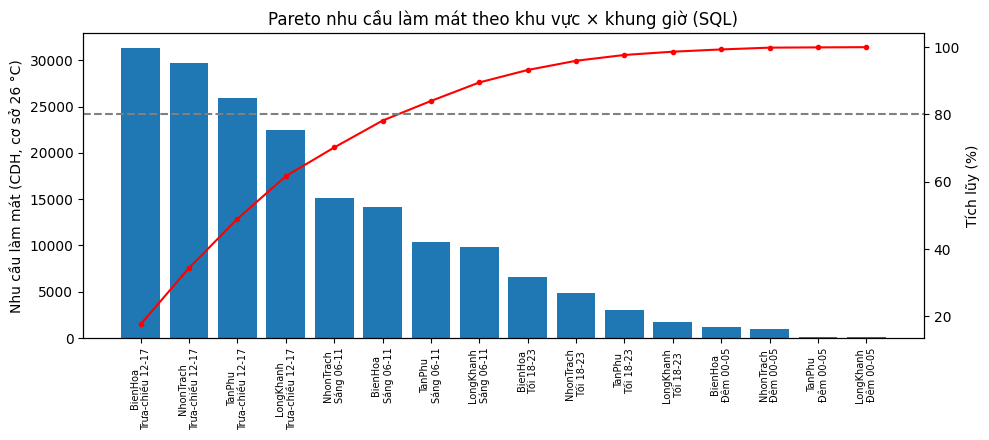

In [10]:
# Ô 10 – Y8: thiết kế SQLite (trạm, giờ, ngày), JOIN và GROUP BY đúng cách, Pareto bằng SQL, khóa ngoại và index
DB = "data/d45_weather.db"
if Path(DB).exists():
    Path(DB).unlink()
con = sqlite3.connect(DB)
con.execute("PRAGMA foreign_keys = ON")
con.executescript("""
CREATE TABLE station (
  station_id INTEGER PRIMARY KEY,
  name TEXT NOT NULL UNIQUE,
  lat REAL NOT NULL, lon REAL NOT NULL);
CREATE TABLE hourly_obs (
  station_id INTEGER NOT NULL REFERENCES station(station_id),
  ts TEXT NOT NULL,
  temp_c REAL, rh REAL, rad_wm2 REAL, precip_mm REAL, wind_kmh REAL,
  cdh REAL, hour_band TEXT,
  PRIMARY KEY (station_id, ts));
CREATE TABLE daily_summary (
  station_id INTEGER NOT NULL REFERENCES station(station_id),
  day TEXT NOT NULL,
  tmax REAL, tmean REAL, precip_sum REAL, cdh_sum REAL, heat_day INTEGER,
  PRIMARY KEY (station_id, day));
CREATE INDEX idx_obs_ts ON hourly_obs(ts);
CREATE INDEX idx_daily_day ON daily_summary(day);
""")


def band(h):
    return "1_Đêm 00-05" if h < 6 else "2_Sáng 06-11" if h < 12 else "3_Trưa-chiều 12-17" if h < 18 else "4_Tối 18-23"


for sid, (name, (lat, lon)) in enumerate(STATIONS.items(), start=1):
    con.execute("INSERT INTO station VALUES (?,?,?,?)", (sid, name, lat, lon))
    h = CLEAN[name].copy()
    h["cdh"] = (h["temperature_2m"] - BASE_CDH).clip(lower=0)
    h["hour_band"] = h["time"].dt.hour.map(band)
    rows = [(sid, t.strftime("%Y-%m-%d %H:%M"), *[None if pd.isna(v) else float(v) for v in vals], b)
            for t, vals, b in zip(h["time"], h[["temperature_2m", "relative_humidity_2m", "shortwave_radiation", "precipitation",
                                                  "wind_speed_10m", "cdh"]].to_numpy(), h["hour_band"])]
    con.executemany("INSERT INTO hourly_obs VALUES (?,?,?,?,?,?,?,?,?)",
                    [(a, b, c, d_, e, f, g, i, j) for (a, b, c, d_, e, f, g, i, j) in rows])
    dd_ = DAILY[name]
    con.executemany("INSERT INTO daily_summary VALUES (?,?,?,?,?,?,?)",
                    [(sid, d.strftime("%Y-%m-%d"), float(v.tmax), float(v.tmean), float(v.precip_sum), float(v.cdh), int(v.tmax >= HEAT))
                     for d, v in dd_.iterrows()])
con.commit()

# toàn vẹn dữ liệu
try:
    con.execute("INSERT INTO hourly_obs (station_id, ts) VALUES (999, '2030-01-01 00:00')")
    fk_blocked = False
except sqlite3.IntegrityError as e:
    fk_blocked = True
    fk_msg = str(e)
fk_violations = con.execute("PRAGMA foreign_key_check").fetchall()
counts = {t: con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0] for t in ("station", "hourly_obs", "daily_summary")}
print("Số dòng:", counts, "| chèn trạm không tồn tại bị chặn:", fk_blocked, f"({fk_msg if fk_blocked else ''})", "| vi phạm khóa ngoại:", len(fk_violations))

# GROUP BY đúng: tỷ lệ ngày nắng nóng = tổng/tổng, không lấy trung bình các tỷ lệ theo tháng
q_right = """SELECT s.name, SUM(d.heat_day) AS heat_days, COUNT(*) AS days, ROUND(SUM(d.heat_day)*1.0/COUNT(*), 4) AS ratio_right
             FROM daily_summary d JOIN station s USING(station_id) GROUP BY s.name ORDER BY heat_days DESC"""
q_wrong = """SELECT name, ROUND(AVG(mr), 4) AS ratio_wrong FROM (
               SELECT s.name, substr(d.day,1,7) AS m, SUM(d.heat_day)*1.0/COUNT(*) AS mr
               FROM daily_summary d JOIN station s USING(station_id) GROUP BY s.name, m) GROUP BY name"""
t_right = pd.read_sql(q_right, con).merge(pd.read_sql(q_wrong, con), on="name")
print("\nTỷ lệ ngày nắng nóng theo khu vực (tổng/tổng so với TB các tỷ lệ tháng):\n", t_right.to_string(index=False))

# bẫy nhân dòng khi JOIN: ghép bảng ngày với bảng giờ rồi SUM → nhân 24 lần; đúng là gộp trước, JOIN sau
bad = con.execute("""SELECT ROUND(SUM(d.precip_sum),1) FROM daily_summary d
                     JOIN hourly_obs o ON o.station_id=d.station_id AND substr(o.ts,1,10)=d.day WHERE d.station_id=1""").fetchone()[0]
good_ = con.execute("SELECT ROUND(SUM(precip_sum),1) FROM daily_summary WHERE station_id=1").fetchone()[0]
chk = con.execute("SELECT ROUND(SUM(precip_mm),1) FROM hourly_obs WHERE station_id=1").fetchone()[0]
rows_join = con.execute("""SELECT COUNT(*) FROM daily_summary d JOIN hourly_obs o
                           ON o.station_id=d.station_id AND substr(o.ts,1,10)=d.day WHERE d.station_id=1""").fetchone()[0]
join_trap = {"sum_wrong_join": bad, "sum_right": good_, "control_total_hourly": chk, "rows_after_join": rows_join,
             "days": int(counts["daily_summary"] / len(STATIONS)), "inflation_factor": r(bad / good_, 2) if good_ else None}
print("\nBẫy JOIN: tổng mưa trạm Biên Hòa — JOIN sai:", bad, "| gộp trước JOIN sau:", good_, "| tổng kiểm tra từ bảng giờ:", chk, f"→ nhân {join_trap['inflation_factor']} lần")

# Pareto bằng SQL: nhu cầu làm mát (CDH) theo khu vực × khung giờ
q_pareto = """
WITH agg AS (
  SELECT s.name AS station, o.hour_band AS band, SUM(o.cdh) AS demand
  FROM hourly_obs o JOIN station s USING(station_id) GROUP BY s.name, o.hour_band),
ranked AS (
  SELECT station, band, demand,
         SUM(demand) OVER (ORDER BY demand DESC ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) * 1.0
           / SUM(demand) OVER () AS cum_share,
         demand * 1.0 / SUM(demand) OVER () AS share
  FROM agg)
SELECT station, band, ROUND(demand,1) AS demand_cdh, ROUND(share,4) AS share, ROUND(cum_share,4) AS cum_share
FROM ranked ORDER BY demand DESC"""
pareto = pd.read_sql(q_pareto, con)
print("\nPareto nhu cầu làm mát (CDH) theo khu vực × khung giờ:\n", pareto.to_string(index=False))
vital = pareto[pareto["cum_share"].shift(fill_value=0) < 0.8]
print(f"→ {len(vital)}/{len(pareto)} nhóm đầu chiếm {vital['share'].sum():.1%} tổng nhu cầu (nhóm 'vital few' theo quy tắc 80%)")

plan = [x[3] for x in con.execute("EXPLAIN QUERY PLAN SELECT * FROM daily_summary WHERE day = '2026-05-01'")]
print("\nKế hoạch truy vấn theo ngày:", plan)

fig, ax = plt.subplots(figsize=(10, 4.5))
lab = pareto["station"] + "\n" + pareto["band"].str[2:]
ax.bar(range(len(pareto)), pareto["demand_cdh"], color="#1f77b4")
ax.set_xticks(range(len(pareto)))
ax.set_xticklabels(lab, rotation=90, fontsize=7)
ax.set_ylabel("Nhu cầu làm mát (CDH, cơ sở 26 °C)")
ax2 = ax.twinx()
ax2.plot(range(len(pareto)), pareto["cum_share"] * 100, color="r", marker="o", ms=3)
ax2.axhline(80, color="gray", ls="--")
ax2.set_ylabel("Tích lũy (%)")
ax.set_title("Pareto nhu cầu làm mát theo khu vực × khung giờ (SQL)")
savefig("y8_pareto")
con.commit()
con.close()
RES["Y8"] = {"db_file": DB, "counts": counts, "fk_blocked": fk_blocked, "fk_violations": len(fk_violations),
             "ratio_table": t_right.to_dict("records"), "join_trap": join_trap, "pareto": pareto.to_dict("records"),
             "vital_few_groups": int(len(vital)), "vital_few_share": r(vital["share"].sum(), 4), "query_plan_day": plan}
save_res()

Số ngày ≥ 35 °C của từng mùa nóng đã quan sát: {2024: 59, 2025: 16, 2026: 34} → TB 36.3
Dự báo số ngày Tmax ≥ ngưỡng trong mùa nóng 2027 (92 ngày, bootstrap khối 7 ngày, B = 5000):
  ngưỡng  dự báo TB (ngày/92)  KTC 95% thấp  KTC 95% cao
   35.0                 39.0          21.0         58.0
   37.0                  5.3           0.0         13.0

Kiểm chứng bỏ một mùa (leave-one-season-out):
  mùa kiểm tra  thực tế (ngày ≥35 °C)  dự báo TB  KTC 95%  nằm trong KTC
         2024                     59       26.6 [12; 44]          False
         2025                     16       49.1 [30; 68]          False
         2026                     34       39.9 [21; 59]           True

T-test Welch giữa các mùa nóng (T3–T5):
      so sánh        TB (°C)  chênh     t            p  Cohen d
2024 vs 2025 35.32 vs 33.66   1.66  7.85 3.380000e-13     1.16
2024 vs 2026 35.32 vs 34.09   1.23  4.81 3.330000e-06     0.71
2025 vs 2026 33.66 vs 34.09  -0.43 -1.69 9.350000e-02    -0.25

Ảnh hưởng cỡ mẫu (2

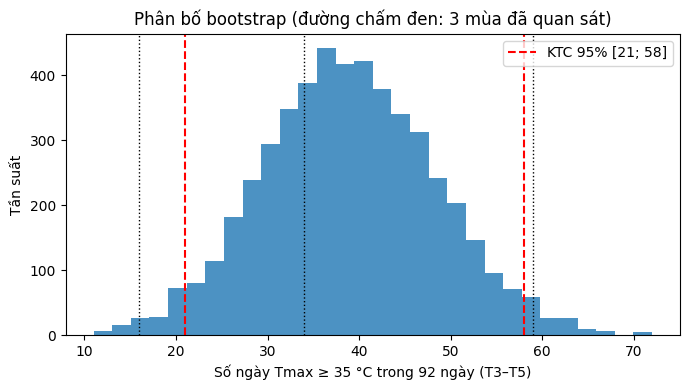

In [11]:
# Ô 11 – Y9: dự báo số ngày vượt ngưỡng 35 °C bằng bootstrap khối; t-test Welch trước/sau; ảnh hưởng cỡ mẫu
def season(yr):
    return y[(y.index >= f"{yr}-03-01") & (y.index <= f"{yr}-05-31")].to_numpy()


SEASONS = {yr: season(yr) for yr in (2024, 2025, 2026)}
L = len(SEASONS[2024])
B, BLOCK = 5000, 7


def boot_counts(train, thr, B=B, block=BLOCK, length=L, rg=rng):
    out = np.empty(B)
    nb = math.ceil(length / block)
    for i in range(B):
        parts = []
        for _ in range(nb):
            s = train[rg.integers(len(train))]
            st = rg.integers(0, len(s) - block + 1)
            parts.append(s[st:st + block])
        out[i] = (np.concatenate(parts)[:length] >= thr).sum()
    return out


def ci(a):
    return float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5))


rows_b = []
for thr in (35.0, 37.0):
    bc = boot_counts(list(SEASONS.values()), thr)
    lo, hi = ci(bc)
    rows_b.append({"ngưỡng": thr, "dự báo TB (ngày/92)": r(bc.mean(), 1), "KTC 95% thấp": r(lo, 1), "KTC 95% cao": r(hi, 1)})
fc_df = pd.DataFrame(rows_b)
season_counts = {yr: int((v >= HEAT).sum()) for yr, v in SEASONS.items()}
print("Số ngày ≥ 35 °C của từng mùa nóng đã quan sát:", season_counts, "→ TB", round(float(np.mean(list(season_counts.values()))), 1))
print(f"Dự báo số ngày Tmax ≥ ngưỡng trong mùa nóng 2027 (92 ngày, bootstrap khối {BLOCK} ngày, B = {B}):\n", fc_df.to_string(index=False))

rows_l = []
for yr in SEASONS:
    train = [v for k, v in SEASONS.items() if k != yr]
    bc = boot_counts(train, HEAT, B=2000)
    lo, hi = ci(bc)
    act = int((SEASONS[yr] >= HEAT).sum())
    rows_l.append({"mùa kiểm tra": yr, "thực tế (ngày ≥35 °C)": act, "dự báo TB": r(bc.mean(), 1),
                   "KTC 95%": f"[{lo:.0f}; {hi:.0f}]", "nằm trong KTC": bool(lo <= act <= hi)})
loo_df = pd.DataFrame(rows_l)
print("\nKiểm chứng bỏ một mùa (leave-one-season-out):\n", loo_df.to_string(index=False))

rows_w = []
for a_yr, b_yr in ((2024, 2025), (2024, 2026), (2025, 2026)):
    A, Bv = SEASONS[a_yr], SEASONS[b_yr]
    t_ = stats.ttest_ind(A, Bv, equal_var=False)
    d_ = (A.mean() - Bv.mean()) / math.sqrt((A.var(ddof=1) + Bv.var(ddof=1)) / 2)
    rows_w.append({"so sánh": f"{a_yr} vs {b_yr}", "TB (°C)": f"{A.mean():.2f} vs {Bv.mean():.2f}", "chênh": r(A.mean() - Bv.mean(), 2),
                   "t": r(t_.statistic, 2), "p": float(f"{t_.pvalue:.3g}"), "Cohen d": r(d_, 2)})
welch_df = pd.DataFrame(rows_w)
print("\nT-test Welch giữa các mùa nóng (T3–T5):\n", welch_df.to_string(index=False))

rows_n = []
for n in (5, 10, 20, 40, 92):
    sig = 0
    for _ in range(1000):
        pa = stats.ttest_ind(rng.choice(SEASONS[2024], n, replace=False), rng.choice(SEASONS[2025], n, replace=False), equal_var=False).pvalue
        sig += pa < 0.05
    rows_n.append({"cỡ mẫu mỗi nhóm": n, "tỷ lệ phát hiện khác biệt (p<0,05)": r(sig / 1000, 3)})
size_df = pd.DataFrame(rows_n)
print("\nẢnh hưởng cỡ mẫu (2024 vs 2025, 1000 lần lấy mẫu con):\n", size_df.to_string(index=False))

bc35 = boot_counts(list(SEASONS.values()), 35.0)
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(bc35, bins=30, color="#1f77b4", alpha=.8)
lo, hi = ci(bc35)
ax.axvline(lo, color="r", ls="--")
ax.axvline(hi, color="r", ls="--", label=f"KTC 95% [{lo:.0f}; {hi:.0f}]")
for yr, v in SEASONS.items():
    ax.axvline((v >= HEAT).sum(), color="k", ls=":", lw=1)
ax.set(xlabel="Số ngày Tmax ≥ 35 °C trong 92 ngày (T3–T5)", ylabel="Tần suất", title="Phân bố bootstrap (đường chấm đen: 3 mùa đã quan sát)")
ax.legend()
savefig("y9_bootstrap")
RES["Y9"] = {"forecast": fc_df.to_dict("records"), "season_counts": season_counts, "leave_one_out": loo_df.to_dict("records"), "welch": welch_df.to_dict("records"),
             "sample_size": size_df.to_dict("records"), "B": B, "block": BLOCK, "season_days": L}
save_res()

In [12]:
# Ô 12 – Y10: báo cáo tự động lên Google Sheets qua Web App (token trong .env, chia lô, thử lại, UPSERT theo ngày)
GS_CODE = r'''
/** Web App nhận dữ liệu từ Python và UPSERT theo cột "date" vào sheet daily_report.
 *  Cách dùng: Extensions → Apps Script → dán mã này → Project Settings → Script properties: TOKEN = <chuỗi bí mật dài>.
 *  Deploy → New deployment → Web app → Execute as: Me; Who has access: Anyone → copy URL (/exec). */
function doPost(e) {
  var out = function (o) { return ContentService.createTextOutput(JSON.stringify(o)).setMimeType(ContentService.MimeType.JSON); };
  try {
    var body = JSON.parse(e.postData.contents);
    var token = PropertiesService.getScriptProperties().getProperty('TOKEN');
    if (!token || body.token !== token) return out({ok: false, code: 401, error: 'unauthorized'});
    var rows = body.rows || [];
    if (!rows.length) return out({ok: false, code: 400, error: 'no rows'});
    var ss = SpreadsheetApp.getActiveSpreadsheet();
    var sh = ss.getSheetByName('daily_report') || ss.insertSheet('daily_report');
    var cols = Object.keys(rows[0]);
    if (sh.getLastRow() === 0) sh.appendRow(cols);
    var keys = sh.getRange(2, 1, Math.max(sh.getLastRow() - 1, 1), 1).getValues().map(function (r) { return String(r[0]); });
    var inserted = 0, updated = 0;
    rows.forEach(function (r) {
      var line = cols.map(function (c) { return r[c] === null ? '' : r[c]; });
      var idx = keys.indexOf(String(r[cols[0]]));
      if (idx >= 0) { sh.getRange(idx + 2, 1, 1, cols.length).setValues([line]); updated++; }
      else { sh.appendRow(line); keys.push(String(r[cols[0]])); inserted++; }
    });
    return out({ok: true, code: 200, inserted: inserted, updated: updated});
  } catch (err) { return out({ok: false, code: 500, error: String(err)}); }
}
'''
Path("apps_script/Code.gs").write_text(GS_CODE.strip() + "\n", encoding="utf-8")
Path(".env.example").write_text("# Sao chép thành .env (KHÔNG nộp, KHÔNG commit)\nD45_WEBAPP_URL=https://script.google.com/macros/s/XXXX/exec\nD45_TOKEN=thay-bang-chuoi-ngau-nhien-dai-it-nhat-32-ky-tu\n")
Path(".gitignore").write_text(".env\nservice_account.json\n__pycache__/\n")


def push_rows(url, token, rows, batch_size=200, max_retry=4, backoff=1.0):
    """Gửi theo lô, thử lại khi lỗi mạng/HTTP 429/5xx; không thử lại khi token sai (401)."""
    st = {"batches": 0, "retries": 0, "inserted": 0, "updated": 0, "codes": []}
    for i in range(0, len(rows), batch_size):
        chunk = rows[i:i + batch_size]
        for attempt in range(max_retry + 1):
            try:
                resp = requests.post(url, json={"token": token, "rows": chunk}, timeout=30)
                if resp.status_code == 429 or resp.status_code >= 500:
                    raise RuntimeError(f"HTTP {resp.status_code}")
                data = resp.json()
                if data.get("code") == 401:
                    raise PermissionError("token sai (401)")
                if not data.get("ok"):
                    raise RuntimeError(f"lỗi Web App: {data.get('error')}")
                st["batches"] += 1
                st["inserted"] += data.get("inserted", 0)
                st["updated"] += data.get("updated", 0)
                st["codes"].append(data.get("code"))
                break
            except PermissionError:
                raise
            except (requests.RequestException, RuntimeError, ValueError):
                st["retries"] += 1
                if attempt == max_retry:
                    raise
                time.sleep(min(backoff * 2 ** attempt, 30))
    return st


def level(t):
    return "GAY GẮT" if t >= SEVERE else "NẮNG NÓNG" if t >= HEAT else "Bình thường"


report = daily.reset_index().assign(date=lambda d: d["date"].dt.strftime("%Y-%m-%d"))
report = report[["date", "tmax", "tmean", "rh_mean", "precip_sum", "cdh"]].round(2)
report["alert"] = report["tmax"].map(level)
report_rows = to_json_records(report)

# --- Kiểm thử Web App giả lập cục bộ (cùng giao thức: token, mã phản hồi, UPSERT theo ngày, lỗi tạm thời) ---
MOCK_TOKEN = secrets.token_urlsafe(32)


class Mock(BaseHTTPRequestHandler):
    store, calls, failed_once = {}, 0, False

    def do_POST(self):
        body = json.loads(self.rfile.read(int(self.headers["Content-Length"])))
        Mock.calls += 1
        if Mock.calls == 2 and not Mock.failed_once:          # mô phỏng lỗi mạng tạm thời ở lô thứ 2
            Mock.failed_once = True
            self.send_response(503)
            self.end_headers()
            return
        if body.get("token") != MOCK_TOKEN:
            res = {"ok": False, "code": 401, "error": "unauthorized"}
        else:
            ins = upd = 0
            for rw in body["rows"]:
                if rw["date"] in Mock.store:
                    upd += 1
                else:
                    ins += 1
                Mock.store[rw["date"]] = rw
            res = {"ok": True, "code": 200, "inserted": ins, "updated": upd}
        raw = json.dumps(res).encode()
        self.send_response(200)
        self.send_header("Content-Type", "application/json")
        self.send_header("Content-Length", str(len(raw)))
        self.end_headers()
        self.wfile.write(raw)

    def log_message(self, *a):
        pass


srv = HTTPServer(("127.0.0.1", 0), Mock)
threading.Thread(target=srv.serve_forever, daemon=True).start()
mock_url = f"http://127.0.0.1:{srv.server_port}/exec"

s1 = push_rows(mock_url, MOCK_TOKEN, report_rows, batch_size=200, backoff=0.05)
rows_after_1 = len(Mock.store)
s2 = push_rows(mock_url, MOCK_TOKEN, report_rows, batch_size=200, backoff=0.05)       # chạy lại: phải UPSERT, không nhân đôi
rows_after_2 = len(Mock.store)
try:
    push_rows(mock_url, "token-sai", report_rows[:5], backoff=0.05)
    wrong_token = "không bị chặn"
except PermissionError as e:
    wrong_token = str(e)
srv.shutdown()
print(f"Lần 1: {s1['batches']} lô, thử lại {s1['retries']} lần, thêm mới {s1['inserted']}, cập nhật {s1['updated']}, mã phản hồi {set(s1['codes'])} → {rows_after_1} dòng")
print(f"Lần 2 (chạy lại): thêm mới {s2['inserted']}, cập nhật {s2['updated']} → {rows_after_2} dòng (không nhân đôi: {rows_after_1 == rows_after_2})")
print("Token sai →", wrong_token, "| độ dài token:", len(MOCK_TOKEN), "ký tự")

# --- Gửi thật (chỉ khi đã đặt biến môi trường / .env) ---
try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass
real = None
if os.getenv("D45_WEBAPP_URL") and os.getenv("D45_TOKEN"):
    real = push_rows(os.environ["D45_WEBAPP_URL"], os.environ["D45_TOKEN"], report_rows)
    print("Gửi thật lên Google Sheets:", {k: v for k, v in real.items() if k != "codes"})
else:
    print("Chưa đặt D45_WEBAPP_URL / D45_TOKEN → bỏ qua bước gửi thật (xem .env.example).")

con = sqlite3.connect(DB)
plan_src = [x[3] for x in con.execute("EXPLAIN QUERY PLAN SELECT * FROM daily_summary WHERE station_id=1 AND day BETWEEN '2026-04-01' AND '2026-04-30'")]
con.close()
RES["Y10"] = {"rows_report": len(report_rows), "batch_size": 200, "run1": {k: v for k, v in s1.items() if k != "codes"},
              "run2": {k: v for k, v in s2.items() if k != "codes"}, "response_codes": sorted({str(c) for c in s1["codes"]}),
              "no_duplicate_on_rerun": rows_after_1 == rows_after_2, "wrong_token_result": wrong_token,
              "token_length": len(MOCK_TOKEN), "real_push": None if real is None else {k: v for k, v in real.items() if k != "codes"},
              "query_plan_source": plan_src, "apps_script_file": "apps_script/Code.gs"}
save_res()

Lần 1: 6 lô, thử lại 1 lần, thêm mới 1096, cập nhật 0, mã phản hồi {200} → 1096 dòng
Lần 2 (chạy lại): thêm mới 0, cập nhật 1096 → 1096 dòng (không nhân đôi: True)
Token sai → token sai (401) | độ dài token: 43 ký tự
Chưa đặt D45_WEBAPP_URL / D45_TOKEN → bỏ qua bước gửi thật (xem .env.example).


In [13]:
# Ô 13 – Tổng kết: độ phủ kiến thức, danh sách file sản phẩm
COVER = {
    "Y1": ["K14.4", "K12.1"], "Y2": ["K13.1", "K13.2"], "Y3": ["K14.2", "K14.3"], "Y4": ["K08.1", "K08.3", "K08.4"],
    "Y5": ["K13.5", "K13.4", "K09.5", "K10.2"], "Y6": ["K05.1", "K05.2", "K05.3", "K06.1", "K06.2"],
    "Y7": ["K09.1", "K09.3", "K07.8"], "Y8": ["K11.1", "K11.2", "K11.4", "K14.1"], "Y9": ["K14.5", "K13.3"],
    "Y10": ["K12.2", "K12.3", "K12.4", "K12.5", "K11.5"]}
codes = sorted({c for v in COVER.values() for c in v})
sessions = sorted({int(c[1:3]) for c in codes})
RES["coverage"] = {"units": len(codes), "of": 49, "percent": r(len(codes) / 49 * 100, 1), "sessions": sessions,
                   "n_sessions": len(sessions), "by_requirement": COVER}
save_res()
print(f"Độ phủ kiến thức: {len(codes)}/49 = {len(codes) / 49:.1%}; số buổi phủ: {len(sessions)}/10 ({sessions})")
print("\nFile sản phẩm:")
for p in sorted(list(Path('.').glob('results_d45.json')) + list(Path('data').glob('*')) + list(Path('figures').glob('*')) + list(Path('apps_script').glob('*'))):
    print(f"  {str(p):38s} {p.stat().st_size / 1024:8.1f} KB")

Độ phủ kiến thức: 32/49 = 65.3%; số buổi phủ: 10/10 ([5, 6, 7, 8, 9, 10, 11, 12, 13, 14])

File sản phẩm:
  apps_script/Code.gs                         1.7 KB
  data/cleaning_log.json                      3.1 KB
  data/d45_weather.db                     13692.0 KB
  data/daily.json                           174.8 KB
  data/daily_bienhoa.csv                     79.6 KB
  data/daily_sample.json                      0.8 KB
  data/hourly_BienHoa.csv                  1186.0 KB
  data/hourly_LongKhanh.csv                1190.9 KB
  data/hourly_NhonTrach.csv                1187.1 KB
  data/hourly_TanPhu.csv                   1184.6 KB
  figures/y1_ols_vs_theilsen.png            119.4 KB
  figures/y2_trend_ma.png                   417.1 KB
  figures/y3_backtest_mae.png                68.5 KB
  figures/y4_correlation.png                129.4 KB
  figures/y5_anova_boxplot.png               34.3 KB
  figures/y6_xbar_r.png                     208.1 KB
  figures/y7_sliding_window.png             12

In [14]:
!zip -r ketqua.zip results_d45.json figures data/d45_weather.db apps_script
from google.colab import files
files.download("ketqua.zip")

  adding: results_d45.json (deflated 76%)
  adding: figures/ (stored 0%)
  adding: figures/y8_pareto.png (deflated 12%)
  adding: figures/y4_correlation.png (deflated 5%)
  adding: figures/y9_bootstrap.png (deflated 15%)
  adding: figures/y5_anova_boxplot.png (deflated 20%)
  adding: figures/y7_sliding_window.png (deflated 5%)
  adding: figures/y2_trend_ma.png (deflated 2%)
  adding: figures/y1_ols_vs_theilsen.png (deflated 7%)
  adding: figures/y6_xbar_r.png (deflated 5%)
  adding: figures/y3_backtest_mae.png (deflated 9%)
  adding: data/d45_weather.db (deflated 77%)
  adding: apps_script/ (stored 0%)
  adding: apps_script/Code.gs (deflated 49%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>